# **Parte 1. Limpieza de datos**
Celda 1. Instalar e importar librerías

In [1]:
# Si fuera necesario, descomentar:
# !pip install -q openpyxl scikit-learn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


Celda 2. Cargamos el dataset completo

In [2]:
ruta = "/content/EESS_HISTORICO.csv.xlsx"

df_original = pd.read_excel(
    ruta,
    sheet_name="EESS_HISTORICO"
)

# Trabajamos sobre una copia.
df = df_original.copy()

print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])

display(df.head())

Cantidad de filas: 101500
Cantidad de columnas: 27


,_id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,impuesto_combustible_liquidos,impuesto_dioxido_carbono,tasa_vial,tasa_municipal,ingresos_brutos,iva,fondo_fiduciario_GNC
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14611,229708,2304,233,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,171691,264203,388,267,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,137442,205897,1324,208,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,161034,239446,356,2421,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,77368,103315,749211,1099,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Celda 3. Revisar la estructura inicial

In [3]:
print("Dimensiones:", df.shape)

print("\nTipos de datos:")
df.info()

print("\nEstadísticos descriptivos:")
display(df.describe(include="all").T)

print("\nNombres de columnas:")
print(df.columns.tolist())

Dimensiones: (101500, 27)

Tipos de datos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101500 entries, 0 to 101499
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   _id                            101500 non-null  int64  
 1   anio                           101500 non-null  int64  
 2   mes                            101500 non-null  int64  
 3   operador                       101500 non-null  object 
 4   nro_inscripcion                101500 non-null  int64  
 5   bandera                        101500 non-null  object 
 6   fecha_de_baja                  6117 non-null    object 
 7   cuit                           101500 non-null  object 
 8   tipo_negocio                   101500 non-null  object 
 9   direccion                      101493 non-null  object 
 10  localidad                      101500 non-null  object 
 11  provincia                      101500 non-null  

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
_id,"101,500.00",NaN,NaN,NaN,"50,750.50","29,300.67",1.00,"25,375.75","50,750.50","76,125.25","101,500.00"
anio,"101,500.00",NaN,NaN,NaN,"18,793.26","21,231.68","2,018.00","2,022.00","2,022.50","45,657.00","45,688.00"
mes,"101,500.00",NaN,NaN,NaN,"17,537.62","22,199.87",1.00,1.00,2.00,"45,627.00","45,658.00"
operador,101500,4382,AUTOMOVIL CLUB ARGENTINO,5305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
nro_inscripcion,"101,500.00",NaN,NaN,NaN,"5,429.24","3,375.75",101.00,"2,261.00","5,537.00","8,323.00","11,525.00"
bandera,101500,22,YPF,37666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha_de_baja,6117,369,18/2022/08,1533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuit,101500,3864,30-50014329-7,5425,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_negocio,101500,12,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,58573,NaN,NaN,NaN,NaN,NaN,NaN,NaN
direccion,101493,6011,AV. CIRCUNVALACIÓN Y SCHMIDT,172,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Nombres de columnas:
['_id', 'anio', 'mes', 'operador', 'nro_inscripcion', 'bandera', 'fecha_de_baja', 'cuit', 'tipo_negocio', 'direccion', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_sin_impuestos', 'precio_con_impuestos', 'volumen', 'precio_surtidor', 'no_novimientos', 'exentos', 'impuesto_combustible_liquidos', 'impuesto_dioxido_carbono', 'tasa_vial', 'tasa_municipal', 'ingresos_brutos', 'iva', 'fondo_fiduciario_GNC']


Celda 4. Normalizamos los nombres de las columnas

In [4]:
import re
import unicodedata

def normalizar_nombre(nombre):
    nombre = str(nombre).strip().lower()

    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )

    nombre = re.sub(r"[^a-z0-9]+", "_", nombre)

    return nombre.strip("_")


df.columns = [
    normalizar_nombre(col)
    for col in df.columns
]

print(df.columns.tolist())

['id', 'anio', 'mes', 'operador', 'nro_inscripcion', 'bandera', 'fecha_de_baja', 'cuit', 'tipo_negocio', 'direccion', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_sin_impuestos', 'precio_con_impuestos', 'volumen', 'precio_surtidor', 'no_novimientos', 'exentos', 'impuesto_combustible_liquidos', 'impuesto_dioxido_carbono', 'tasa_vial', 'tasa_municipal', 'ingresos_brutos', 'iva', 'fondo_fiduciario_gnc']


Celda 5. Limpiamos espacios y cadenas vacías

In [5]:
columnas_texto = df.select_dtypes(
    include=["object", "string"]
).columns

for col in columnas_texto:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Convertir cadenas vacías en nulos.
df = df.replace(r"^\s*$", np.nan, regex=True)

print("Limpieza básica de textos completada.")
display(df.head())

Limpieza básica de textos completada.


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,impuesto_combustible_liquidos,impuesto_dioxido_carbono,tasa_vial,tasa_municipal,ingresos_brutos,iva,fondo_fiduciario_gnc
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14611,229708,2304,233,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,171691,264203,388,267,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,137442,205897,1324,208,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,161034,239446,356,2421,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,77368,103315,749211,1099,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Celda 6. Corregimos anio y mes

Resultado esperado: los períodos que estaban almacenados como números de Excel deberían quedar identificados como diciembre de 2024 y enero de 2025.
No creamos meses inexistentes ni modificamos la cobertura real.

In [6]:
def normalizar_anio(valor):
    if pd.isna(valor):
        return np.nan

    valor = float(valor)

    if valor > 30000:
        fecha = pd.to_datetime(
            valor,
            unit="D",
            origin="1899-12-30"
        )
        return fecha.year

    return int(valor)


def normalizar_mes(valor):
    if pd.isna(valor):
        return np.nan

    valor = float(valor)

    if valor > 30000:
        fecha = pd.to_datetime(
            valor,
            unit="D",
            origin="1899-12-30"
        )
        return fecha.month

    return int(valor)


df["anio"] = df["anio"].apply(normalizar_anio).astype("Int64")
df["mes"] = df["mes"].apply(normalizar_mes).astype("Int64")

# Validación
print("Distribución de períodos:")
display(
    df.groupby(["anio", "mes"], dropna=False)
      .size()
      .rename("cantidad_registros")
      .reset_index()
      .sort_values(["anio", "mes"])
)

Distribución de períodos:


,anio,mes,cantidad_registros
0,2018,1,2250
1,2019,1,3500
2,2020,1,7750
3,2021,1,2250
4,2022,1,21881
5,2022,2,13119
6,2023,1,7500
7,2024,1,4250
8,2024,12,21601
9,2025,1,17399


Celda 7. Convertimos los tipos de datos

In [7]:
columnas_numericas = [
    "precio_sin_impuestos",
    "precio_con_impuestos",
    "volumen",
    "precio_surtidor",
    "impuesto_combustible_liquidos",
    "impuesto_dioxido_carbono",
    "tasa_vial",
    "tasa_municipal",
    "ingresos_brutos",
    "iva",
    "fondo_fiduciario_gnc"
]

for col in columnas_numericas:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col],
            errors="coerce"
        )

if "fecha_de_baja" in df.columns:
    df["fecha_de_baja"] = pd.to_datetime(
        df["fecha_de_baja"],
        errors="coerce",
        dayfirst=True
    )

# Los identificadores se conservan como texto.
for col in ["cuit", "nro_inscripcion"]:
    if col in df.columns:
        df[col] = df[col].astype("string")

df["anio"] = df["anio"].astype("Int64")
df["mes"] = df["mes"].astype("Int64")

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101500 entries, 0 to 101499
Data columns (total 27 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   id                             101500 non-null  int64         
 1   anio                           101500 non-null  Int64         
 2   mes                            101500 non-null  Int64         
 3   operador                       101500 non-null  string        
 4   nro_inscripcion                101500 non-null  string        
 5   bandera                        101500 non-null  string        
 6   fecha_de_baja                  0 non-null       datetime64[ns]
 7   cuit                           101500 non-null  string        
 8   tipo_negocio                   101500 non-null  string        
 9   direccion                      101493 non-null  string        
 10  localidad                      101500 non-null  string        
 11  

/tmp/ipykernel_8951/2692691010.py:23: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["fecha_de_baja"] = pd.to_datetime(


No convertimos no_novimientos ni exentos en variables numéricas porque sus valores representan categorías o indicadores, no magnitudes continuas.

Celda 8. Revisamos los valores faltantes

In [8]:
resumen_nulos = pd.DataFrame({
    "cantidad_nulos": df.isna().sum(),
    "porcentaje_nulos": (
        df.isna().mean() * 100
    ).round(2)
}).sort_values(
    "porcentaje_nulos",
    ascending=False
)

display(resumen_nulos)

,cantidad_nulos,porcentaje_nulos
fecha_de_baja,101500,100.00
fondo_fiduciario_gnc,66098,65.12
iva,63970,63.02
tasa_municipal,62856,61.93
ingresos_brutos,62856,61.93
impuesto_combustible_liquidos,62856,61.93
tasa_vial,62856,61.93
impuesto_dioxido_carbono,62856,61.93
exentos,1032,1.02
direccion,7,0.01


Ahora generamos un gráfico de los porcentajes de nulos.

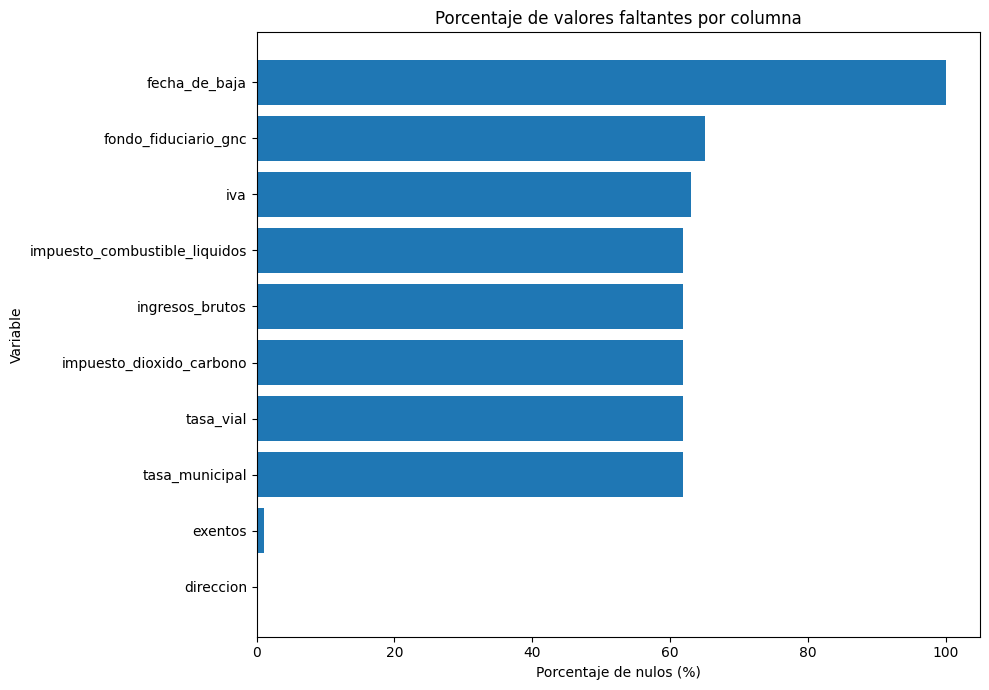

In [9]:
nulos_grafico = resumen_nulos[
    resumen_nulos["cantidad_nulos"] > 0
].sort_values("porcentaje_nulos")

plt.figure(figsize=(10, 7))

plt.barh(
    nulos_grafico.index,
    nulos_grafico["porcentaje_nulos"]
)

plt.title("Porcentaje de valores faltantes por columna")
plt.xlabel("Porcentaje de nulos (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

No imputamos automáticamente todos los nulos. Los campos impositivos tienen faltantes estructurales asociados con la cobertura temporal, mientras que fecha_de_baja puede estar vacía por razones funcionales.

Celda 9. Identificamos y tratamos duplicados

In [10]:
duplicados_exactos = df.duplicated().sum()

print("Duplicados exactos:", duplicados_exactos)

# Revisar duplicados por clave candidata de negocio.
clave_candidata = [
    "nro_inscripcion",
    "anio",
    "mes",
    "producto"
]

duplicados_clave = df.duplicated(
    subset=clave_candidata,
    keep=False
).sum()

print(
    "Filas que pertenecen a combinaciones repetidas "
    "de estación, período y producto:",
    duplicados_clave
)

Duplicados exactos: 0
Filas que pertenecen a combinaciones repetidas de estación, período y producto: 16941


Como no hay duplicados exactos en el archivo, no es necesario eliminarlos. Tampoco debemos eliminar las claves de negocio repetidas: pueden representar registros válidos de la misma estación y producto.

Celda 10. Detectar valores inválidos y sospechosos

In [11]:
print(
    "Volúmenes negativos:",
    (df["volumen"] < 0).sum()
)

print(
    "Volúmenes iguales a cero:",
    (df["volumen"] == 0).sum()
)

print(
    "Años fuera del rango esperado:",
    (~df["anio"].between(2018, 2025)).sum()
)

print(
    "Meses inválidos:",
    (~df["mes"].between(1, 12)).sum()
)

print(
    "Precios sin impuestos mayores que precios con impuestos:",
    (df["precio_sin_impuestos"] >
     df["precio_con_impuestos"]).sum()
)

print(
    "Precio con impuestos distinto de precio surtidor:",
    (df["precio_con_impuestos"] !=
     df["precio_surtidor"]).sum()
)

Volúmenes negativos: 0
Volúmenes iguales a cero: 1032
Años fuera del rango esperado: 0
Meses inválidos: 0
Precios sin impuestos mayores que precios con impuestos: 59707
Precio con impuestos distinto de precio surtidor: 55117


Celda 11. Analizamos los registros sin movimientos

In [12]:
sin_movimientos = df[
    df["no_novimientos"]
      .astype("string")
      .str.upper()
      .eq("SI")
].copy()

print("Registros sin movimientos:", len(sin_movimientos))

display(
    sin_movimientos[
        [
            "anio",
            "mes",
            "producto",
            "canal_de_comercializacion",
            "volumen",
            "precio_sin_impuestos",
            "precio_con_impuestos",
            "precio_surtidor",
            "no_novimientos"
        ]
    ].head(10)
)

Registros sin movimientos: 1032


,anio,mes,producto,canal_de_comercializacion,volumen,precio_sin_impuestos,precio_con_impuestos,precio_surtidor,no_novimientos
5,2018,1,N/D,N/D,0,0,0,0,SI
136,2018,1,N/D,N/D,0,0,0,0,SI
210,2018,1,N/D,N/D,0,0,0,0,SI
294,2018,1,N/D,N/D,0,0,0,0,SI
463,2018,1,N/D,N/D,0,0,0,0,SI
497,2018,1,N/D,N/D,0,0,0,0,SI
720,2018,1,N/D,N/D,0,0,0,0,SI
736,2018,1,N/D,N/D,0,0,0,0,SI
918,2018,1,N/D,N/D,0,0,0,0,SI
981,2018,1,N/D,N/D,0,0,0,0,SI


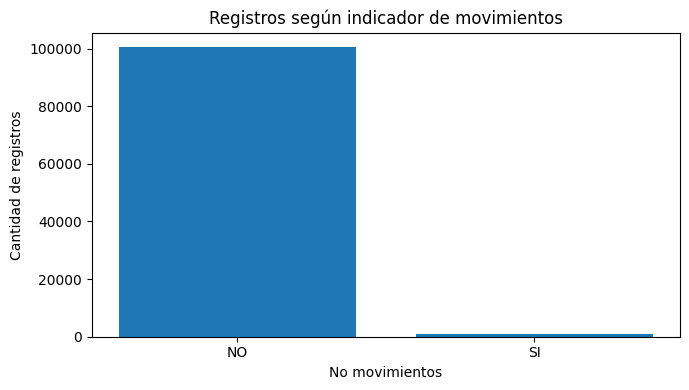

In [13]:
##Gráfico de registros con y sin movimientos:
conteo_movimientos = (
    df["no_novimientos"]
    .value_counts(dropna=False)
)

plt.figure(figsize=(7, 4))

plt.bar(
    conteo_movimientos.index.astype(str),
    conteo_movimientos.values
)

plt.title("Registros según indicador de movimientos")
plt.xlabel("No movimientos")
plt.ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

Conservamos todos estos registros en df. Más adelante definiremos una población específica para entrenar los modelos.

Celda 12. Revisamos valores extremos sin eliminarlos

In [14]:
percentiles = df["volumen"].quantile(
    [0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1]
)

display(percentiles.to_frame("volumen"))

,volumen
0.00,0.00
0.25,"1,486.00"
0.50,"8,198.00"
0.75,"42,315.25"
0.90,"131,567.50"
0.95,"240,641.50"
0.99,"753,003.23"
1.00,"43,290,900.00"


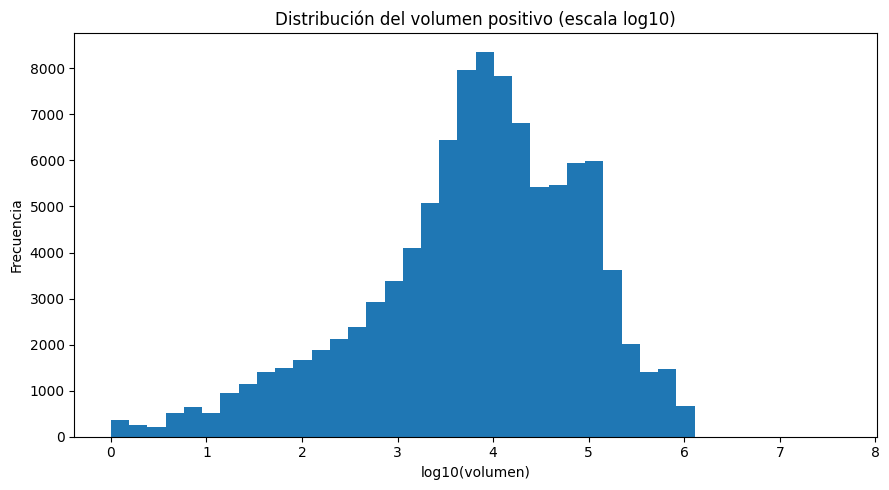

In [15]:
##Gráfico del volumen en escala logarítmica:
volumen_positivo = df.loc[
    df["volumen"] > 0,
    "volumen"
]

plt.figure(figsize=(9, 5))

plt.hist(
    np.log10(volumen_positivo),
    bins=40
)

plt.title("Distribución del volumen positivo (escala log10)")
plt.xlabel("log10(volumen)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

La transformación se utiliza aquí solamente para visualizar mejor la distribución. No modifica los valores originales del dataset.

Celda 13. Creamos el dataset limpio.

Para mantener la trazabilidad, conservamos df_original y guardamos una copia de los datos normalizados.

In [16]:
df_limpio = df.copy()

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df_limpio.shape)

df_limpio.to_csv(
    "/content/EESS_limpio.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo limpio guardado.")

Dimensiones originales: (101500, 27)
Dimensiones después de la limpieza: (101500, 27)
Archivo limpio guardado.


# **Parte 2. Análisis exploratorio de datos (EDA)**
Celda 14. Resumen estadístico del dataset limpio

In [17]:
print("Cantidad de estaciones identificadas:",
      df_limpio["nro_inscripcion"].nunique())

print("Cantidad de productos:",
      df_limpio["producto"].nunique())

print("Cantidad de operadores:",
      df_limpio["operador"].nunique())

print("Cantidad de provincias:",
      df_limpio["provincia"].nunique())

display(
    df_limpio[
        [
            "volumen",
            "precio_sin_impuestos",
            "precio_con_impuestos",
            "precio_surtidor"
        ]
    ].describe().T
)

Cantidad de estaciones identificadas: 6070
Cantidad de productos: 10
Cantidad de operadores: 4374
Cantidad de provincias: 24


,count,mean,std,min,25%,50%,75%,max
volumen,"101,500.00","53,590.15","220,123.99",0.00,"1,486.00","8,198.00","42,315.25","43,290,900.00"
precio_sin_impuestos,"101,500.00","220,427.10","305,758.08",0.00,"13,073.75","81,434.50","194,777.75","999,995.00"
precio_con_impuestos,"101,500.00","71,588.63","163,062.47",0.00,"1,163.00","5,369.00","107,163.00","999,971.00"
precio_surtidor,"101,500.00","4,018.81","28,088.62",0.00,760.00,"1,174.00","1,472.00","999,001.00"


Celda 15. Distribución de productos

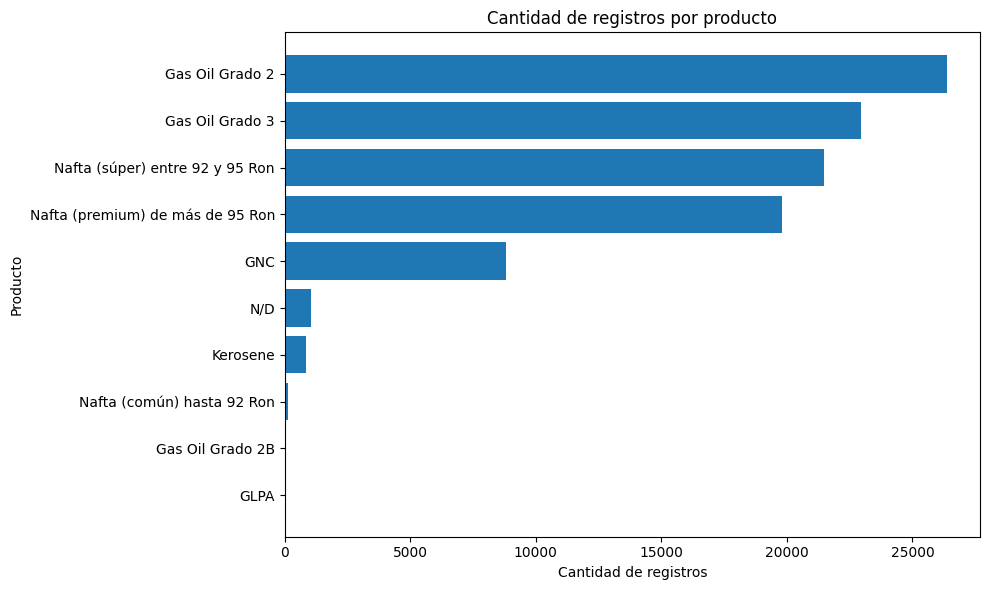

In [18]:
conteo_productos = (
    df_limpio["producto"]
    .value_counts()
    .sort_values()
)

plt.figure(figsize=(10, 6))

plt.barh(
    conteo_productos.index,
    conteo_productos.values
)

plt.title("Cantidad de registros por producto")
plt.xlabel("Cantidad de registros")
plt.ylabel("Producto")
plt.tight_layout()
plt.show()

Este gráfico permite observar qué productos tienen mayor presencia en el dataset. La cantidad de registros no equivale necesariamente al volumen comercializado.

Celda 16. Distribución del volumen por producto.

Para evitar que las diferencias extremas oculten la distribución de otros productos, mostramos un boxplot con escala logarítmica.

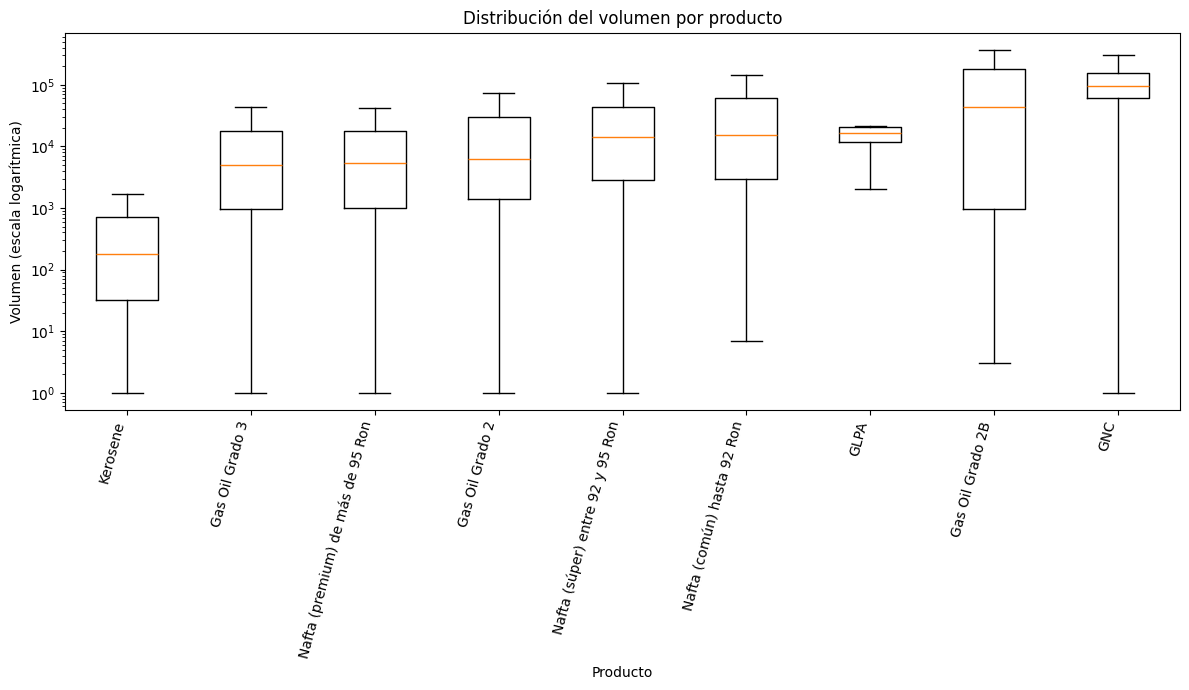

In [19]:
df_eda = df_limpio[
    (df_limpio["volumen"] > 0) &
    (df_limpio["producto"].notna()) &
    (df_limpio["producto"] != "N/D")
].copy()

productos_ordenados = (
    df_eda.groupby("producto")["volumen"]
    .median()
    .sort_values()
    .index
)

datos_boxplot = [
    df_eda.loc[
        df_eda["producto"] == producto,
        "volumen"
    ].values
    for producto in productos_ordenados
]

plt.figure(figsize=(12, 7))

plt.boxplot(
    datos_boxplot,
    tick_labels=productos_ordenados,
    showfliers=False
)

plt.yscale("log")
plt.xticks(rotation=75, ha="right")

plt.title("Distribución del volumen por producto")
plt.xlabel("Producto")
plt.ylabel("Volumen (escala logarítmica)")
plt.tight_layout()
plt.show()

Se excluyen los ceros solamente de esta visualización para poder utilizar la escala logarítmica. No se eliminan de la base original.

Celda 17. Volumen por provincia

In [20]:
volumen_provincia = (
    df_limpio.groupby("provincia")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_provincia.head(15))

,volumen_total,volumen_mediano,cantidad_registros
provincia,,,
BUENOS AIRES,1971504586,"8,798.00",35985
CORDOBA,816636414,"7,174.00",14483
SANTA FE,466358226,"4,365.50",11552
MENDOZA,284034127,"17,761.00",4089
CAPITAL FEDERAL,273802933,"15,130.00",3702
ENTRE RIOS,216507779,"6,937.00",4546
TUCUMAN,189136323,"9,403.00",2640
SALTA,138631346,"11,325.00",1857
RIO NEGRO,134660897,"13,711.00",1993


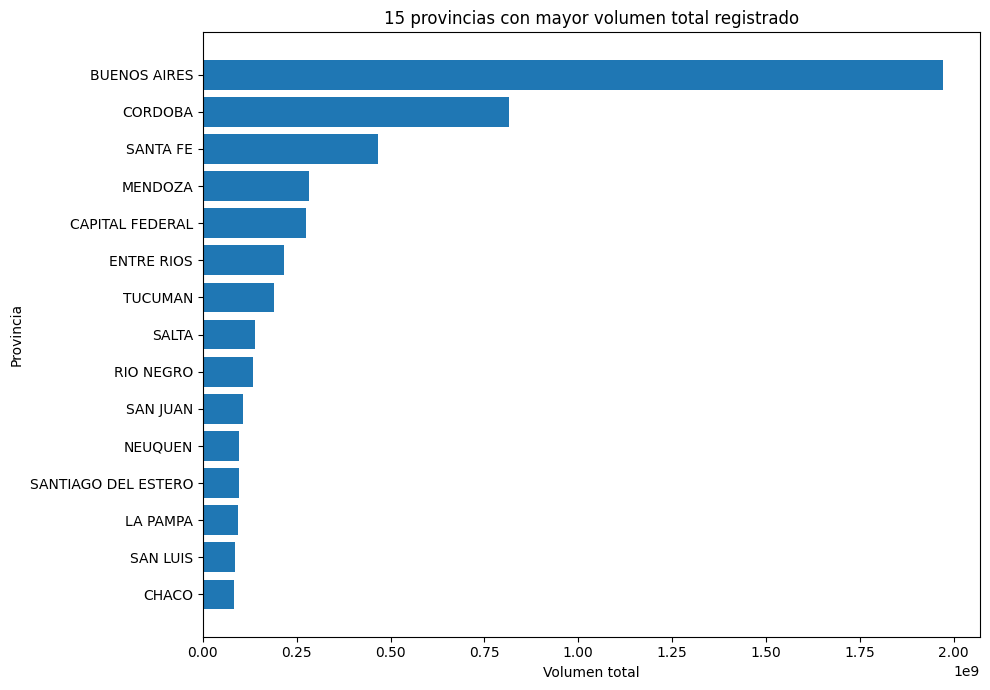

In [21]:
## Gráfico de las 15 provincias con mayor volumen total observado
top_provincias = volumen_provincia.head(15).sort_values(
    "volumen_total"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_provincias.index,
    top_provincias["volumen_total"]
)

plt.title("15 provincias con mayor volumen total registrado")
plt.xlabel("Volumen total")
plt.ylabel("Provincia")
plt.tight_layout()
plt.show()

Interpretación: este gráfico representa el volumen acumulado de los registros disponibles, no una comparación de demanda anual completa. La cobertura temporal y la cantidad de estaciones por provincia pueden influir en el resultado.

Celda 18. Volumen por bandera

In [22]:
volumen_bandera = (
    df_limpio.groupby("bandera")
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size")
    )
    .sort_values("volumen_total", ascending=False)
)

display(volumen_bandera.head(15))

,volumen_total,volumen_mediano,cantidad_registros
bandera,,,
YPF,2216385600,"11,887.00",37666
SHELL C.A.P.S.A.,854367672,"8,295.50",17814
BLANCA,832991653,"3,721.00",15679
AXION,567043561,"7,333.00",9993
PUMA,318432462,"4,746.00",6331
ESSO PETROLERA ARGENTINA S.R.L,174529864,"6,537.50",3934
OIL COMBUSTIBLES S.A.,108065163,"5,170.50",2226
REFINOR,83593452,"4,016.00",1695
PETROBRAS,80537626,"6,943.00",1612


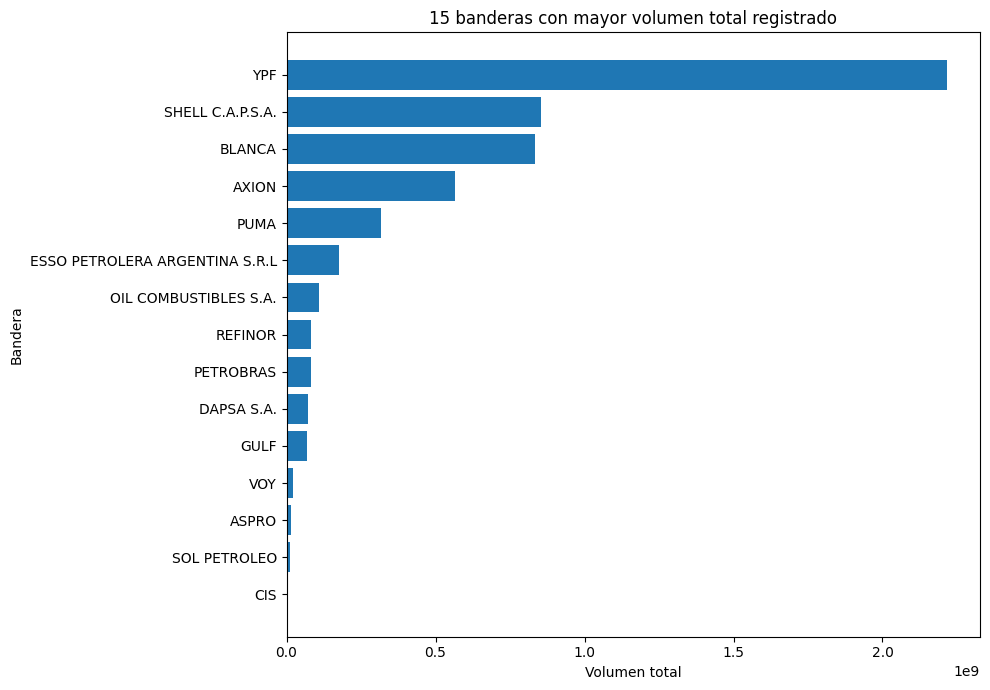

In [23]:
##Gráfico
top_banderas = volumen_bandera.head(15).sort_values(
    "volumen_total"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_banderas.index,
    top_banderas["volumen_total"]
)

plt.title("15 banderas con mayor volumen total registrado")
plt.xlabel("Volumen total")
plt.ylabel("Bandera")
plt.tight_layout()
plt.show()

La mediana por registro y el volumen total responden preguntas diferentes. Por eso conviene revisar ambas métricas.

Celda 19. Evolución por período

In [24]:
evolucion = (
    df_limpio.groupby(["anio", "mes"])
    .agg(
        volumen_total=("volumen", "sum"),
        volumen_mediano=("volumen", "median"),
        cantidad_registros=("volumen", "size"),
        estaciones=("nro_inscripcion", "nunique")
    )
    .reset_index()
    .sort_values(["anio", "mes"])
)

evolucion["periodo"] = (
    evolucion["anio"].astype(str)
    + "-"
    + evolucion["mes"].astype(str).str.zfill(2)
)

display(evolucion)

,anio,mes,volumen_total,volumen_mediano,cantidad_registros,estaciones,periodo
0,2018,1,94964432,"7,886.00",2250,610,2018-01
1,2019,1,156637849,"7,244.50",3500,907,2019-01
2,2020,1,364034451,"7,935.50",7750,1994,2020-01
3,2021,1,84506602,"6,470.00",2250,578,2021-01
4,2022,1,1116136828,"8,105.00",21881,5438,2022-01
5,2022,2,675341781,"7,835.00",13119,3299,2022-02
6,2023,1,363075908,"7,775.50",7500,1905,2023-01
7,2024,1,206954193,"6,604.50",4250,1093,2024-01
8,2024,12,1337707637,"9,425.00",21601,5385,2024-12
9,2025,1,1040040933,"8,942.00",17399,4348,2025-01


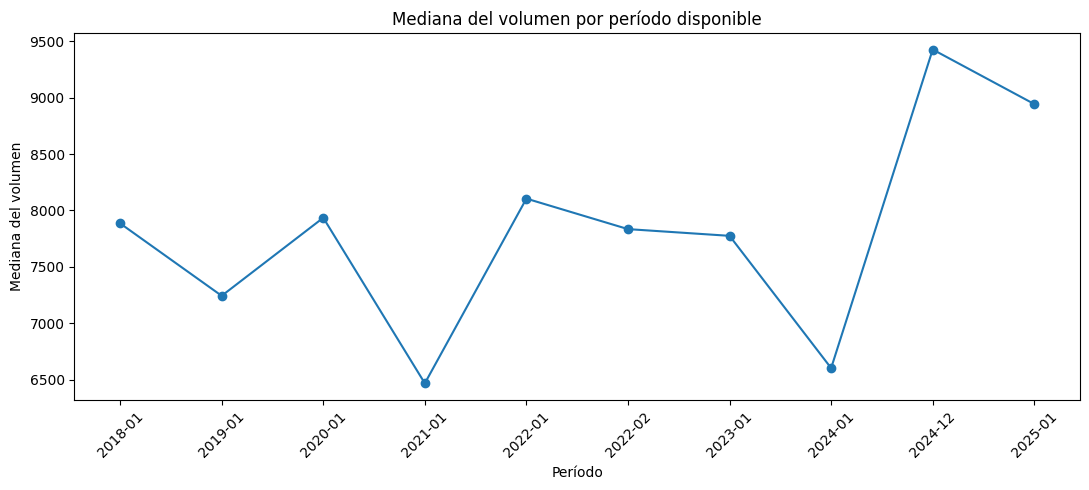

In [25]:
## Gráfico
plt.figure(figsize=(11, 5))

plt.plot(
    evolucion["periodo"],
    evolucion["volumen_mediano"],
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Mediana del volumen por período disponible")
plt.xlabel("Período")
plt.ylabel("Mediana del volumen")
plt.tight_layout()
plt.show()

Este gráfico muestra únicamente los períodos informados. No representa una serie mensual continua y no permite inferir estacionalidad.

Celda 20. Relación entre precio de surtidor y volumen.

Como los precios necesitan validación semántica, este gráfico debe interpretarse como exploratorio y no como evidencia causal.

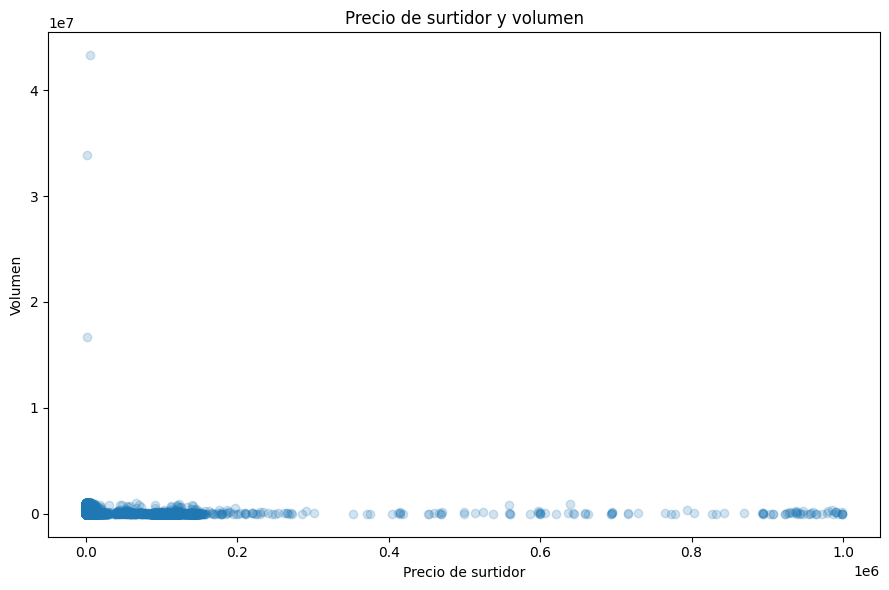

In [26]:
df_precios = df_limpio[
    (df_limpio["precio_surtidor"] > 0) &
    (df_limpio["volumen"] > 0)
].copy()

plt.figure(figsize=(9, 6))

plt.scatter(
    df_precios["precio_surtidor"],
    df_precios["volumen"],
    alpha=0.2
)

plt.title("Precio de surtidor y volumen")
plt.xlabel("Precio de surtidor")
plt.ylabel("Volumen")
plt.tight_layout()
plt.show()

Para una interpretación válida, luego deberíamos separar el análisis por producto y período. Una correlación global podría mezclar combustibles y condiciones comerciales diferentes.

Celda 21. Matriz de correlación numérica

In [27]:
columnas_corr = [
    "volumen",
    "precio_sin_impuestos",
    "precio_con_impuestos",
    "precio_surtidor"
]

correlacion = df_limpio[columnas_corr].corr(
    method="spearman"
)

display(correlacion)

,volumen,precio_sin_impuestos,precio_con_impuestos,precio_surtidor
volumen,1.00,0.07,0.04,0.15
precio_sin_impuestos,0.07,1.00,0.27,-0.00
precio_con_impuestos,0.04,0.27,1.00,0.25
precio_surtidor,0.15,-0.00,0.25,1.00


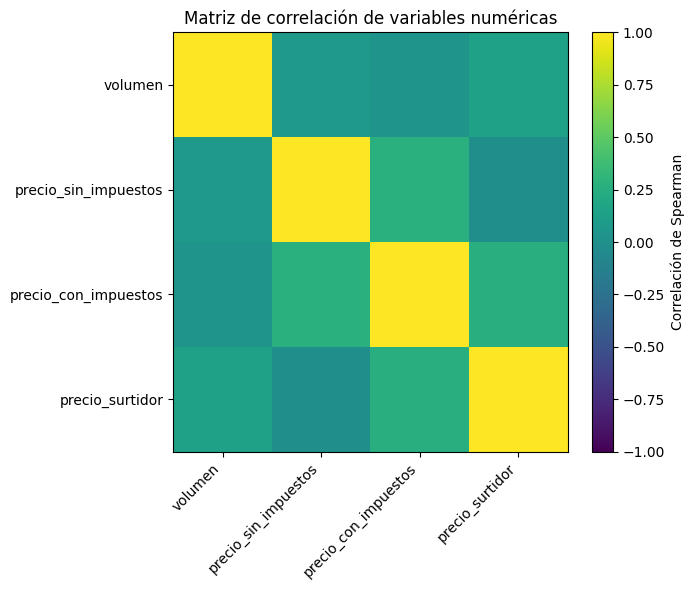

In [28]:
## Gráfico
plt.figure(figsize=(7, 6))

plt.imshow(
    correlacion,
    aspect="auto",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlación de Spearman")

plt.xticks(
    range(len(correlacion.columns)),
    correlacion.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlacion.index)),
    correlacion.index
)

plt.title("Matriz de correlación de variables numéricas")
plt.tight_layout()
plt.show()

La correlación de Spearman permite explorar asociaciones monotónicas. No demuestra causalidad y puede estar afectada por las diferencias de escala o por la mezcla de productos.

Celda 22. Definir el conjunto para modelado.

Excluimos los registros sin movimientos y los que no tienen un producto identificado. Así el modelo se concentra en observaciones con actividad comercial.

In [29]:

import pandas as pd
import numpy as np

# Verificar columnas necesarias
columnas_necesarias = [
    "volumen",
    "nro_inscripcion",
    "producto",
    "no_novimientos"
]

faltantes = [
    c for c in columnas_necesarias
    if c not in df.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas necesarias: {faltantes}")

# Trabajar sobre una copia
df_modelo = df.copy()

# Normalizar texto de las columnas utilizadas en el filtro
df_modelo["producto"] = (
    df_modelo["producto"].astype("string").str.strip()
)

df_modelo["no_novimientos"] = (
    df_modelo["no_novimientos"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# Convertir target a numérico
df_modelo["volumen"] = pd.to_numeric(
    df_modelo["volumen"],
    errors="coerce"
)

# Excluir filas sin target, con volumen negativo,
# sin producto identificado o sin movimientos
df_modelo = df_modelo[
    df_modelo["volumen"].notna()
    & (df_modelo["volumen"] >= 0)
    & df_modelo["producto"].notna()
    & (df_modelo["producto"].str.upper() != "N/D")
    & (df_modelo["no_novimientos"] == "NO")
    & df_modelo["nro_inscripcion"].notna()
].copy()

df_modelo.reset_index(drop=True, inplace=True)

print("Filas para modelado:", len(df_modelo))
print("Estaciones únicas:", df_modelo["nro_inscripcion"].nunique())
print("Volumen mínimo:", df_modelo["volumen"].min())
print("Volumen máximo:", df_modelo["volumen"].max())

display(df_modelo.head())


Filas para modelado: 100468
Estaciones únicas: 5883
Volumen mínimo: 1
Volumen máximo: 43290900


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos,impuesto_combustible_liquidos,impuesto_dioxido_carbono,tasa_vial,tasa_municipal,ingresos_brutos,iva,fondo_fiduciario_gnc
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaT,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14611,229708,2304,233,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaT,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,171691,264203,388,267,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaT,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,137442,205897,1324,208,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaT,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,161034,239446,356,2421,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaT,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,77368,103315,749211,1099,NO,f,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Esta decisión define la población que vamos a modelar. No significa que los registros sin movimientos sean necesariamente errores: se excluyen porque el objetivo es estudiar el volumen de las observaciones con actividad.

Celda 23. Definir la variable target y los predictores.

La variable objetivo será volumen. Excluimos identificadores, datos que podrían identificar directamente una estación y variables monetarias que pueden tener una relación matemática directa con el volumen. También excluimos campos que no estarán disponibles de manera consistente o que no corresponden al objetivo.

In [30]:

# Variable que queremos predecir
target = "volumen"

# Columnas que no utilizaremos como predictores
columnas_excluir = [
    "_id",
    "volumen",
    "nro_inscripcion",
    "cuit",
    "direccion",
    "fecha_de_baja",
    "no_novimientos",
    "exentos",
    "precio_sin_impuestos",
    "precio_con_impuestos",
    "precio_surtidor",
    "impuesto_combustible_liquidos",
    "impuesto_dioxido_carbono",
    "tasa_vial",
    "tasa_municipal",
    "ingresos_brutos",
    "iva",
    "fondo_fiduciario_gnc"
]

# Considerar únicamente columnas que existen en el dataset
columnas_excluir = [
    c for c in columnas_excluir
    if c in df_modelo.columns
]

# X conserva nro_inscripcion temporalmente para agrupar
# las filas durante la separación de los datos
columnas_predictoras = [
    c for c in df_modelo.columns
    if c not in columnas_excluir
]

X = df_modelo[columnas_predictoras + ["nro_inscripcion"]].copy()
y = df_modelo[target].copy()
grupos = df_modelo["nro_inscripcion"].copy()

print("Variable target:", target)
print("Cantidad de predictores:", len(columnas_predictoras))
print("Predictores:", columnas_predictoras)

display(
    pd.DataFrame({
        "Variable": columnas_predictoras
    })
)

Variable target: volumen
Cantidad de predictores: 10
Predictores: ['id', 'anio', 'mes', 'operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']


,Variable
0,id
1,anio
2,mes
3,operador
4,bandera
5,tipo_negocio
6,localidad
7,provincia
8,producto
9,canal_de_comercializacion


Celda 24. Separar entrenamiento y prueba.

Reservamos el 20 % de los datos para la evaluación final. Usamos GroupShuffleSplit para que todas las observaciones de una misma estación queden en un solo conjunto.

In [31]:

from sklearn.model_selection import GroupShuffleSplit

separador = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

indices_train, indices_test = next(
    separador.split(X, y, groups=grupos)
)

X_train = X.iloc[indices_train].copy()
X_test = X.iloc[indices_test].copy()

y_train = y.iloc[indices_train].copy()
y_test = y.iloc[indices_test].copy()

# Guardar los grupos correspondientes a cada fila
grupos_train = X_train["nro_inscripcion"].copy()
grupos_test = X_test["nro_inscripcion"].copy()

# Verificar que no haya estaciones compartidas
estaciones_train = set(grupos_train.unique())
estaciones_test = set(grupos_test.unique())

compartidas = estaciones_train.intersection(estaciones_test)

print("Filas de entrenamiento:", len(X_train))
print("Filas de prueba:", len(X_test))
print("Estaciones en entrenamiento:", len(estaciones_train))
print("Estaciones en prueba:", len(estaciones_test))
print("Estaciones compartidas:", len(compartidas))

# Quitar el identificador de estación de los predictores
X_train_model = X_train.drop(
    columns=["nro_inscripcion"]
).copy()

X_test_model = X_test.drop(
    columns=["nro_inscripcion"]
).copy()

assert len(compartidas) == 0, (
    "Error: hay estaciones presentes en ambos conjuntos."
)

Filas de entrenamiento: 80623
Filas de prueba: 19845
Estaciones en entrenamiento: 4706
Estaciones en prueba: 1177
Estaciones compartidas: 0


Celda 25. **Preparar el preprocesamiento**

Los modelos necesitan que las variables categóricas se conviertan a formato numérico. Además, vamos a imputar valores faltantes dentro de cada pipeline para que el preprocesamiento se ajuste exclusivamente con los datos de entrenamiento de cada pliegue.

In [32]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identificar columnas numéricas y categóricas
columnas_numericas = X_train_model.select_dtypes(
    include=["number"]
).columns.tolist()

columnas_categoricas = X_train_model.select_dtypes(
    exclude=["number"]
).columns.tolist()

# Preprocesamiento numérico
transformador_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento categórico
transformador_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combinar transformaciones
preprocessor = ColumnTransformer([
    (
        "numericas",
        transformador_numerico,
        columnas_numericas
    ),
    (
        "categoricas",
        transformador_categorico,
        columnas_categoricas
    )
])

print("Variables numéricas:", columnas_numericas)
print("Variables categóricas:", columnas_categoricas)
print("Preprocesamiento definido correctamente.")

Variables numéricas: ['id', 'anio', 'mes']
Variables categóricas: ['operador', 'bandera', 'tipo_negocio', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion']
Preprocesamiento definido correctamente.


Celda 26. **Definir los tres modelos**

In [33]:

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

modelos = {
    "Regresión Lineal": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", LinearRegression())
    ]),

    "Árbol de Decisión": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", DecisionTreeRegressor(
            max_depth=12,
            min_samples_leaf=20,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocesamiento", preprocessor),
        ("modelo", RandomForestRegressor(
            n_estimators=200,
            max_depth=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Modelos definidos:")
for nombre in modelos:
    print("-", nombre)

Modelos definidos:
- Regresión Lineal
- Árbol de Decisión
- Random Forest


Celda 27. **Configuramos la validación cruzada**

Utilizamos cinco pliegues con GroupKFold. En cada pliegue, las estaciones de validación serán distintas de las estaciones usadas para entrenar ese modelo.

In [34]:

from sklearn.model_selection import GroupKFold, cross_validate

cv = GroupKFold(n_splits=5)

print("Cantidad de pliegues:", cv.get_n_splits())
print("Método: GroupKFold")
print("Variable de agrupación: nro_inscripcion")

Cantidad de pliegues: 5
Método: GroupKFold
Variable de agrupación: nro_inscripcion


Celda 28. **Ejecutamos la validación cruzada**

Evaluamos cada modelo usando MAE, RMSE y R². La validación se realiza únicamente sobre el conjunto de entrenamiento; el conjunto de prueba permanece reservado.

In [35]:

resultados_cv = []

for nombre, modelo in modelos.items():

    resultados = cross_validate(
        estimator=modelo,
        X=X_train_model,
        y=y_train,
        groups=grupos_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        # Evita paralelismo anidado con Random Forest
        n_jobs=1,
        return_train_score=False
    )

    resultados_cv.append({
        "Modelo": nombre,
        "MAE promedio": -resultados["test_MAE"].mean(),
        "MAE desvío": resultados["test_MAE"].std(),
        "RMSE promedio": -resultados["test_RMSE"].mean(),
        "RMSE desvío": resultados["test_RMSE"].std(),
        "R2 promedio": resultados["test_R2"].mean(),
        "R2 desvío": resultados["test_R2"].std()
    })

tabla_cv = pd.DataFrame(resultados_cv)

tabla_cv = tabla_cv.sort_values(
    by="MAE promedio",
    ascending=True
).reset_index(drop=True)

display(tabla_cv.round(3))

,Modelo,MAE promedio,MAE desvío,RMSE promedio,RMSE desvío,R2 promedio,R2 desvío
0,Random Forest,"59,099.00","3,240.98","187,747.74","140,091.68",0.11,0.05
1,Árbol de Decisión,"61,279.70","3,290.28","192,920.33","137,236.37",0.03,0.07
2,Regresión Lineal,"69,289.78","3,911.66","194,336.45","137,682.61",0.01,0.04


**RECORDATORIO**
Cómo interpretar los resultados:
- Un MAE menor indica menor error absoluto promedio.
- Un RMSE menor indica menos penalización acumulada por errores grandes.
- Un R² más cercano a 1 suele ser mejor; puede ser negativo si el modelo rinde peor que una predicción basada en la media.
- Un desvío bajo entre pliegues sugiere que el resultado es más estable.

Celda 29. **Comparar los modelos visualmente**

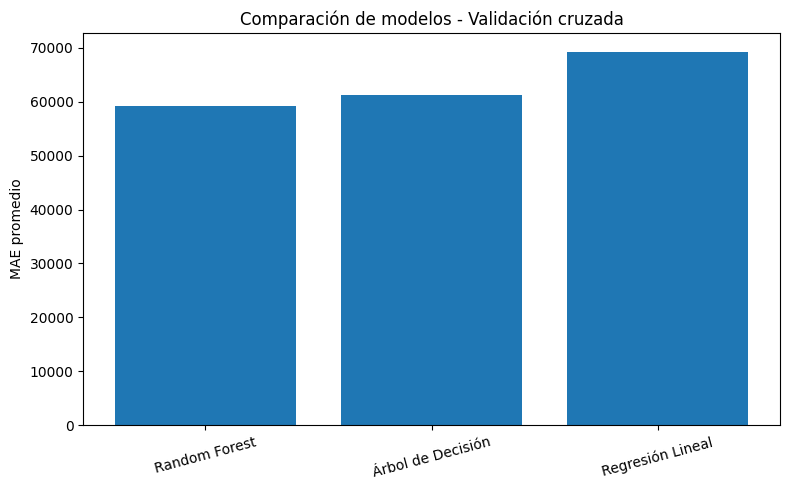

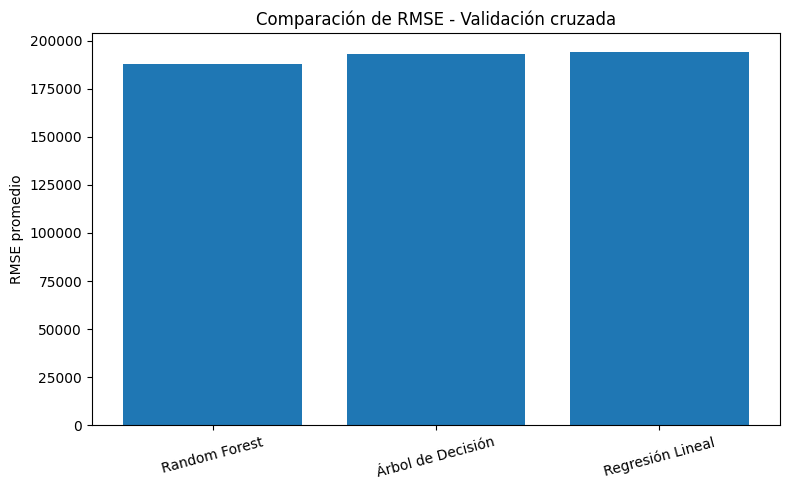

In [36]:

import matplotlib.pyplot as plt

# Comparación de MAE
plt.figure(figsize=(8, 5))
plt.bar(
    tabla_cv["Modelo"],
    tabla_cv["MAE promedio"]
)
plt.ylabel("MAE promedio")
plt.title("Comparación de modelos - Validación cruzada")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Comparación de RMSE
plt.figure(figsize=(8, 5))
plt.bar(
    tabla_cv["Modelo"],
    tabla_cv["RMSE promedio"]
)
plt.ylabel("RMSE promedio")
plt.title("Comparación de RMSE - Validación cruzada")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Celda 30. **Seleccionar el modelo candidato**

Como criterio inicial, elegimos el modelo con menor MAE promedio. Después revisaremos sus métricas y estabilidad antes de sacar conclusiones.

In [ ]:

mejor_nombre = tabla_cv.iloc[0]["Modelo"]
mejor_modelo = modelos[mejor_nombre]

print("Modelo candidato:", mejor_nombre)
print(
    "MAE promedio CV:",
    round(tabla_cv.iloc[0]["MAE promedio"], 3)
)
print(
    "Desvío MAE CV:",
    round(tabla_cv.iloc[0]["MAE desvío"], 3)
)
print(
    "RMSE promedio CV:",
    round(tabla_cv.iloc[0]["RMSE promedio"], 3)
)
print(
    "R² promedio CV:",
    round(tabla_cv.iloc[0]["R2 promedio"], 3)
)

Celda 30 BIS. **Entrenar los tres modelos y generar predicciones**

In [37]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

resultados_prueba = []
predicciones = {}

for nombre, modelo in modelos.items():

    print(f"Entrenando y evaluando: {nombre}", flush=True)

    # Entrenar usando todos los datos de entrenamiento
    modelo.fit(X_train_model, y_train)

    # Predecir sobre el mismo conjunto de prueba
    y_pred_modelo = modelo.predict(X_test_model)

    # Guardar las predicciones para analizarlas después
    predicciones[nombre] = y_pred_modelo

    # Calcular métricas
    mae = mean_absolute_error(y_test, y_pred_modelo)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred_modelo))
    r2 = r2_score(y_test, y_pred_modelo)

    resultados_prueba.append({
        "Modelo": nombre,
        "MAE prueba": mae,
        "RMSE prueba": rmse,
        "R2 prueba": r2
    })

tabla_prueba = pd.DataFrame(resultados_prueba)

tabla_prueba = tabla_prueba.sort_values(
    by="MAE prueba",
    ascending=True
).reset_index(drop=True)

display(tabla_prueba.round(3))

Entrenando y evaluando: Regresión Lineal
Entrenando y evaluando: Árbol de Decisión
Entrenando y evaluando: Random Forest


,Modelo,MAE prueba,RMSE prueba,R2 prueba
0,Random Forest,"57,957.75","117,108.54",0.10
1,Árbol de Decisión,"59,633.37","120,915.57",0.05
2,Regresión Lineal,"66,756.27","124,434.52",-0.01


Celda 31. **Comparar los tres modelos contra el baseline**

El baseline predice la mediana del volumen observado en entrenamiento para todas las filas de prueba. Es una referencia sencilla, importante porque el volumen tiene una distribución muy asimétrica.

In [38]:

# Baseline: predecir siempre la mediana del entrenamiento
pred_baseline = np.full(
    len(y_test),
    y_train.median()
)

mae_baseline = mean_absolute_error(y_test, pred_baseline)

rmse_baseline = np.sqrt(
    mean_squared_error(y_test, pred_baseline)
)

r2_baseline = r2_score(y_test, pred_baseline)

# Agregar el baseline a la tabla comparativa
fila_baseline = pd.DataFrame([{
    "Modelo": "Baseline - mediana",
    "MAE prueba": mae_baseline,
    "RMSE prueba": rmse_baseline,
    "R2 prueba": r2_baseline
}])

comparacion_final = pd.concat(
    [tabla_prueba, fila_baseline],
    ignore_index=True
)

display(
    comparacion_final.sort_values(
        by="MAE prueba"
    ).round(3)
)

,Modelo,MAE prueba,RMSE prueba,R2 prueba
3,Baseline - mediana,"50,403.68","131,535.88",-0.13
0,Random Forest,"57,957.75","117,108.54",0.10
1,Árbol de Decisión,"59,633.37","120,915.57",0.05
2,Regresión Lineal,"66,756.27","124,434.52",-0.01


**RECORDATORIO** ❣
Interpretación:
- Si un modelo tiene menor MAE que el baseline, mejora el error absoluto medio de esa referencia.
- Si también tiene menor RMSE, reduce el error cuadrático medio.
- Un R² bajo o negativo puede indicar que el modelo tiene poca capacidad predictiva para estos datos.

Celda 32. **Calcular la mejora frente al baseline**

Esta celda expresa en porcentaje cuánto mejora o empeora cada modelo el MAE respecto del baseline.

In [39]:

comparacion_mejora = comparacion_final.copy()

comparacion_mejora["Mejora MAE vs baseline (%)"] = (
    (mae_baseline - comparacion_mejora["MAE prueba"])
    / mae_baseline
) * 100

comparacion_mejora["Mejora RMSE vs baseline (%)"] = (
    (rmse_baseline - comparacion_mejora["RMSE prueba"])
    / rmse_baseline
) * 100

display(
    comparacion_mejora.sort_values(
        by="MAE prueba"
    ).round(2)
)

,Modelo,MAE prueba,RMSE prueba,R2 prueba,Mejora MAE vs baseline (%),Mejora RMSE vs baseline (%)
3,Baseline - mediana,"50,403.68","131,535.87",-0.13,0.00,0.00
0,Random Forest,"57,957.75","117,108.54",0.10,-14.99,10.97
1,Árbol de Decisión,"59,633.37","120,915.57",0.05,-18.31,8.07
2,Regresión Lineal,"66,756.28","124,434.52",-0.01,-32.44,5.40


Un porcentaje positivo indica mejora respecto del baseline; uno negativo indica que el modelo empeora esa métrica.

¿Qué pasos seguirías para intentar mejorar el rendimiento del Random Forest?
Para mejorar el rendimiento del modelo Random Forest en este conjunto de datos, te sugiero seguir una estrategia estructurada en las siguientes áreas:

1. Ingeniería de Características (Feature Engineering)
Actualmente los predictores se limitan a la información geográfica, temporal y de catálogo. El volumen es una variable de negocio muy ligada al comportamiento histórico:

Agregar variables agregadas por Estación (nro_inscripcion): Crear características que capturen el tamaño o comportamiento histórico de la estación (por ejemplo, el volumen promedio histórico de la estación, el número de productos que ofrece, o su antigüedad).
Codificación de variables de alta cardinalidad: Variables como localidad u operador tienen miles de categorías. En lugar de usar One-Hot Encoding (que genera una matriz extremadamente dispersa y dificulta el aprendizaje del árbol), es mejor probar con Target Encoding o agrupar las categorías menos frecuentes en una clase 'Otros'.
Características temporales cíclicas: Transformar el mes utilizando funciones seno y coseno para que el modelo entienda que diciembre (12) y enero (1) son meses contiguos.
2. Tratamiento de la Distribución del Target
El volumen tiene una distribución extremadamente asimétrica (con valores que van desde 1 hasta más de 43 millones):

Transformación Logarítmica: Entrenar el Random Forest para predecir $\log(volumen)$$\log(volumen)$ en lugar del volumen directo. Esto reduce drásticamente el impacto de los valores extremos (outliers) durante la partición de los nodos. Al evaluar, simplemente aplicas la función exponencial para devolver las predicciones a su escala original.
3. Ajuste de Hiperparámetros (Hyperparameter Tuning)
El modelo actual tiene restricciones fijas que podrían estar limitando su capacidad de aprendizaje o provocando un subajuste (underfitting):

Realizar una búsqueda sistemática usando GridSearchCV o RandomizedSearchCV (manteniendo siempre la estructura GroupKFold para evitar fuga de datos) evaluando los siguientes parámetros:
max_depth: Probar valores más profundos o permitir que se expanda por completo si el sobreajuste se controla con otros parámetros.
min_samples_leaf: Probar valores más pequeños (ej. 1, 2, 3) para permitir que el modelo capture patrones más específicos.
max_features: Evaluar `

Celda 33. **Comparar visualmente las métricas**

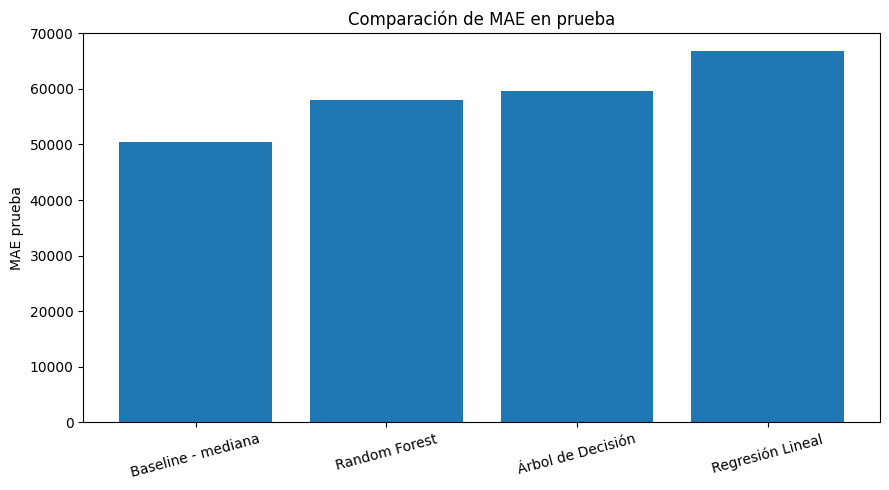

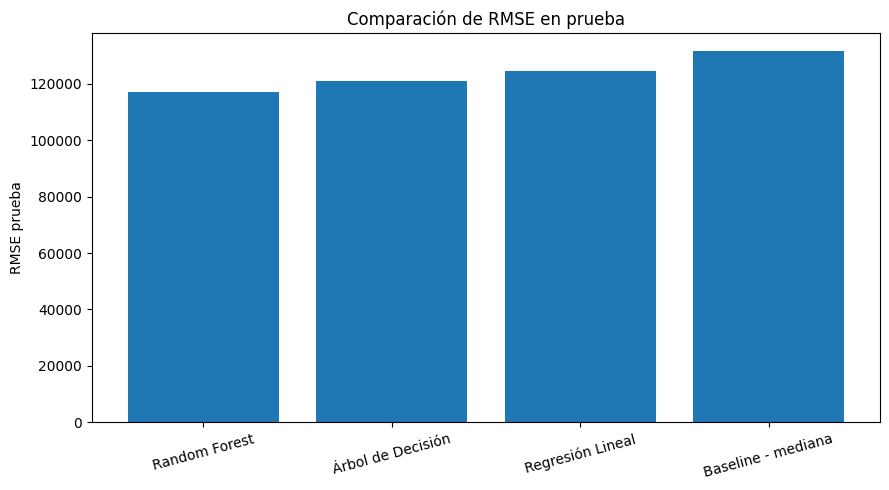

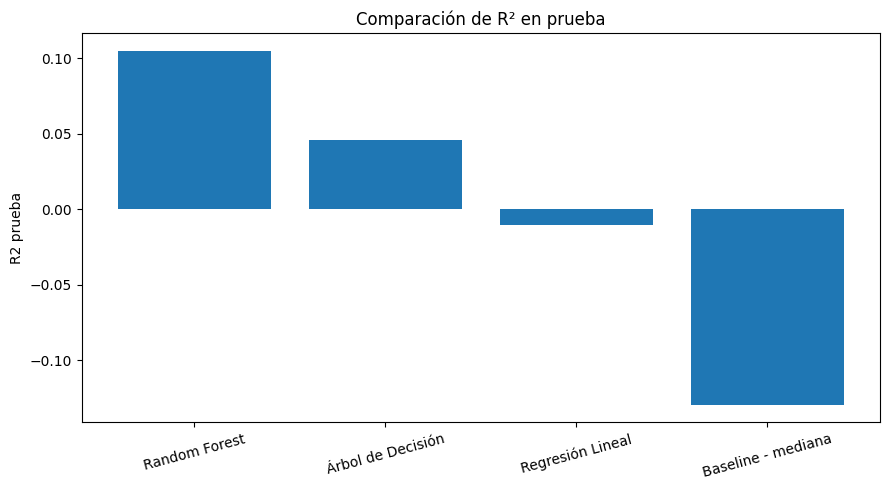

In [40]:

metricas = [
    ("MAE prueba", "Comparación de MAE en prueba"),
    ("RMSE prueba", "Comparación de RMSE en prueba"),
    ("R2 prueba", "Comparación de R² en prueba")
]

for columna, titulo in metricas:

    datos = comparacion_final.sort_values(
        by=columna,
        ascending=(columna != "R2 prueba")
    )

    plt.figure(figsize=(9, 5))

    plt.bar(
        datos["Modelo"],
        datos[columna]
    )

    plt.ylabel(columna)
    plt.title(titulo)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

Estos gráficos incluyen el baseline. Para MAE y RMSE, los valores menores son mejores; para R², los valores mayores suelen ser preferibles.

Celda 34. **Graficar valores reales versus predichos para los tres modelos**

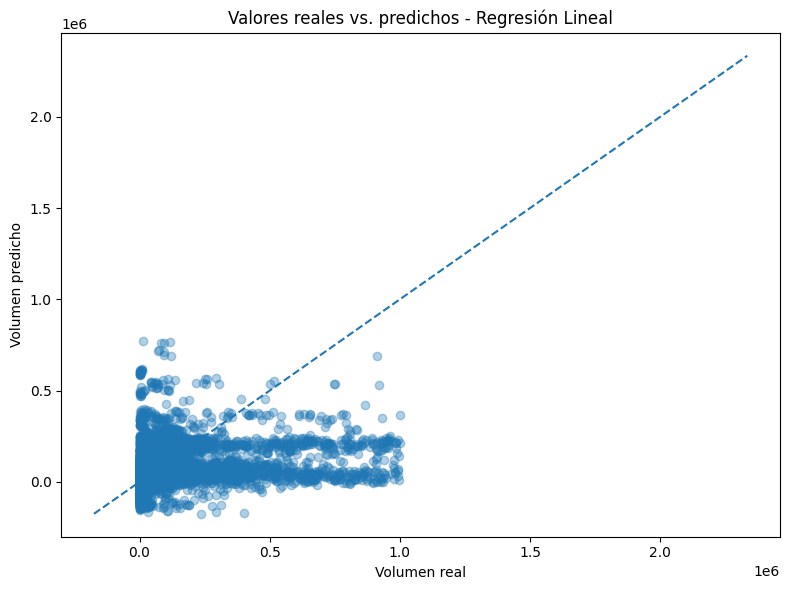

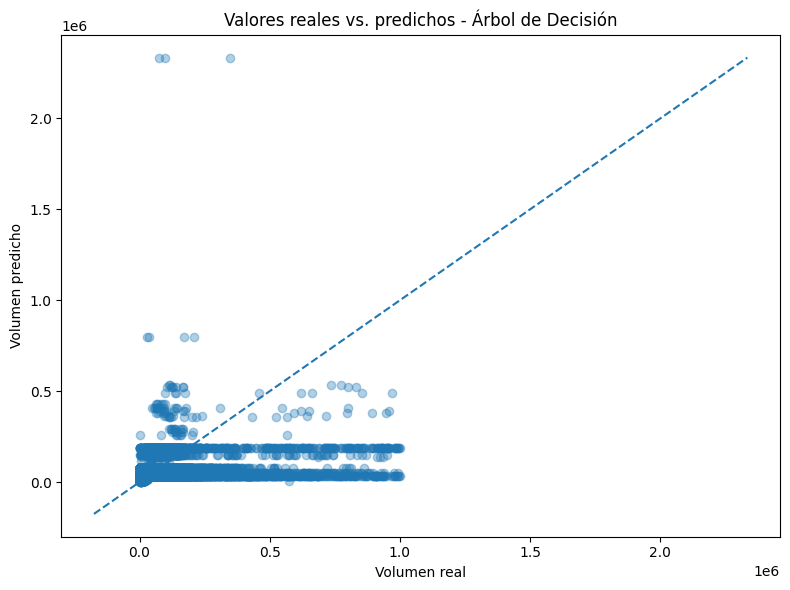

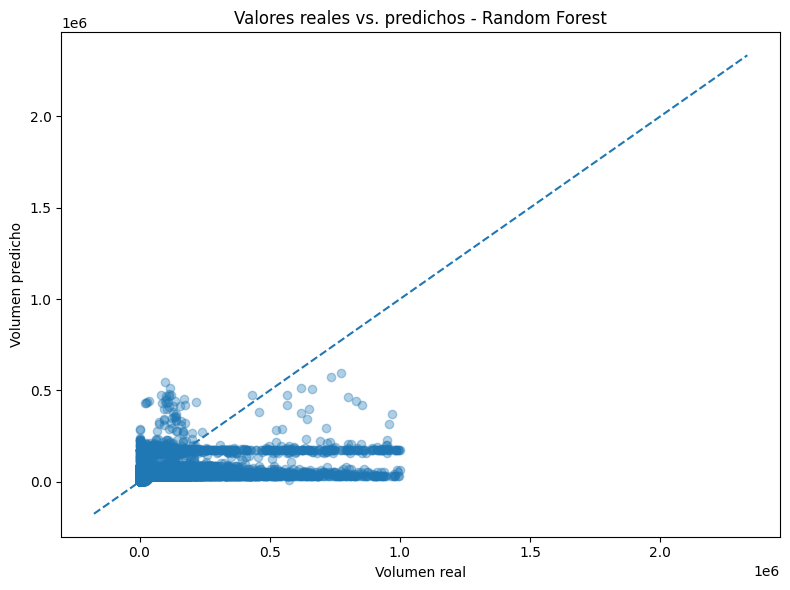

In [41]:

minimo = min(
    float(y_test.min()),
    min(float(np.min(p)) for p in predicciones.values())
)

maximo = max(
    float(y_test.max()),
    max(float(np.max(p)) for p in predicciones.values())
)

for nombre, y_pred_modelo in predicciones.items():

    plt.figure(figsize=(8, 6))

    plt.scatter(
        y_test,
        y_pred_modelo,
        alpha=0.35
    )

    plt.plot(
        [minimo, maximo],
        [minimo, maximo],
        linestyle="--"
    )

    plt.xlabel("Volumen real")
    plt.ylabel("Volumen predicho")
    plt.title(f"Valores reales vs. predichos - {nombre}")
    plt.tight_layout()
    plt.show()

La diagonal representa la predicción perfecta. Observá especialmente si los modelos subestiman los volúmenes grandes o producen predicciones demasiado concentradas.

Celda 35. **Analizar los residuos de los tres modelos**

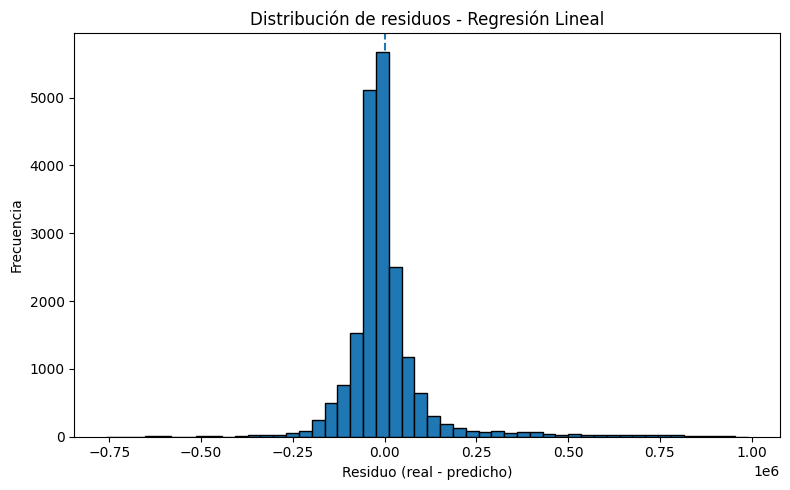


Regresión Lineal
Residuo medio: 1,539.06
Error absoluto mediano: 35,855.52


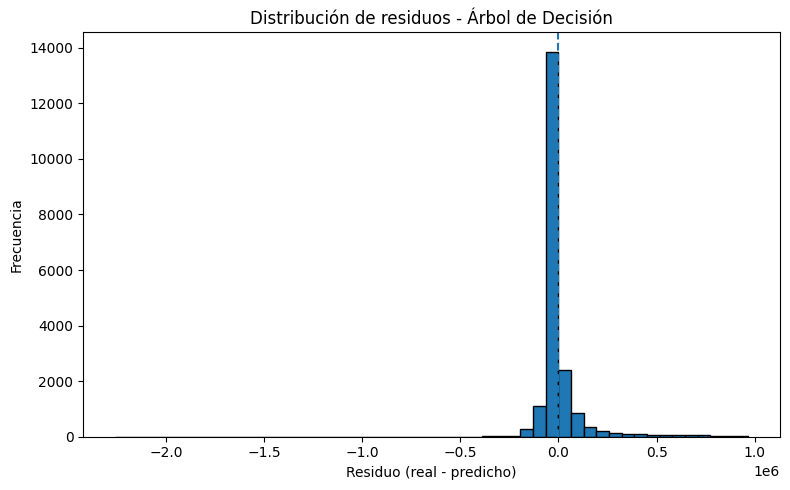


Árbol de Decisión
Residuo medio: 655.34
Error absoluto mediano: 32,404.81


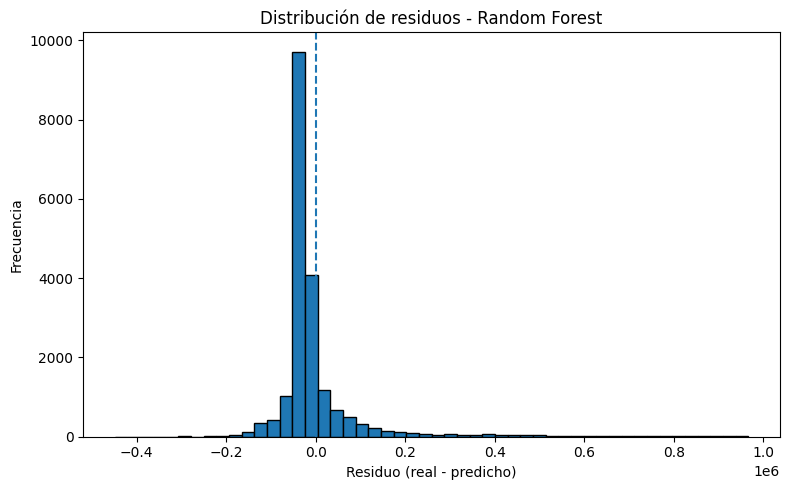


Random Forest
Residuo medio: 2,581.78
Error absoluto mediano: 30,740.59


In [42]:

for nombre, y_pred_modelo in predicciones.items():

    residuos = np.asarray(y_test) - np.asarray(y_pred_modelo)

    plt.figure(figsize=(8, 5))

    plt.hist(
        residuos,
        bins=50,
        edgecolor="black"
    )

    plt.axvline(
        0,
        linestyle="--"
    )

    plt.xlabel("Residuo (real - predicho)")
    plt.ylabel("Frecuencia")
    plt.title(f"Distribución de residuos - {nombre}")
    plt.tight_layout()
    plt.show()

    print(f"\n{nombre}")
    print(f"Residuo medio: {residuos.mean():,.2f}")
    print(
        "Error absoluto mediano:",
        f"{np.median(np.abs(residuos)):,.2f}"
    )

Celda 36. **Analizar la importancia de variables de los modelos de árboles**

Esta última celda permite examinar los dos modelos basados en árboles. No se aplica a la Regresión Lineal mediante este método de importancia.

Top 15 variables - Árbol de Decisión


,Variable,Importancia
4670,categoricas__producto_GNC,0.39
0,numericas__id,0.22
493,categoricas__operador_CABARO S.R.L,0.15
4677,categoricas__producto_Nafta (súper) entre 92 y 95 Ron,0.03
3540,categoricas__bandera_YPF,0.02
1087,categoricas__operador_EL CONVOY S.R.L.,0.02
4438,categoricas__localidad_SAN MIGUEL DE TUCUMAN,0.01
152,categoricas__operador_ALGARROBITOS S.A.,0.01
20,categoricas__operador_9 DE JULIO SERVICIOS SRL,0.01
312,categoricas__operador_AUTOMOVIL CLUB ARGENTINO,0.01


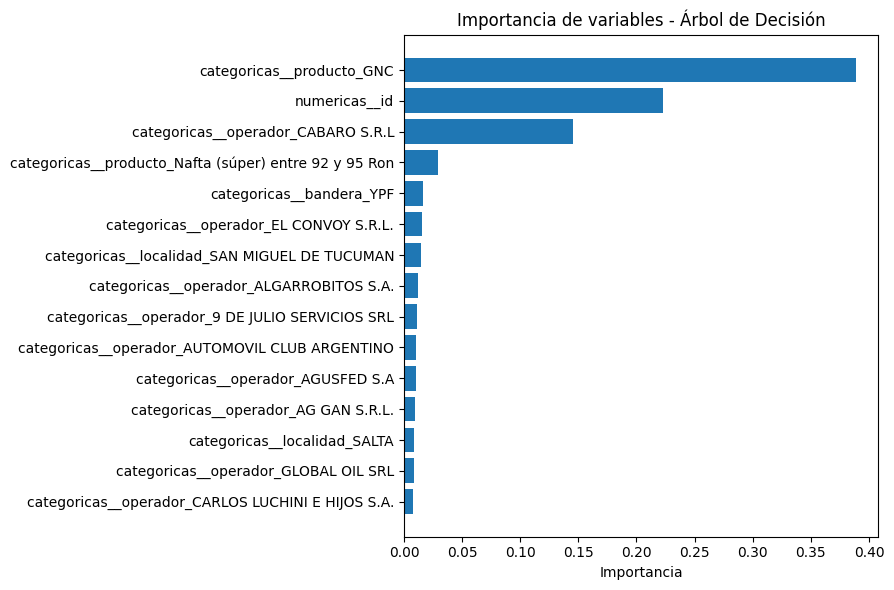

Top 15 variables - Random Forest


,Variable,Importancia
0,numericas__id,0.23
4670,categoricas__producto_GNC,0.19
2776,categoricas__operador_PROINCO SA,0.14
493,categoricas__operador_CABARO S.R.L,0.07
1233,categoricas__operador_ESTACION CENTRAL S.R.L.,0.05
2,numericas__mes,0.04
4673,categoricas__producto_Gas Oil Grado 3,0.04
1,numericas__anio,0.03
4677,categoricas__producto_Nafta (súper) entre 92 y 95 Ron,0.01
3540,categoricas__bandera_YPF,0.01


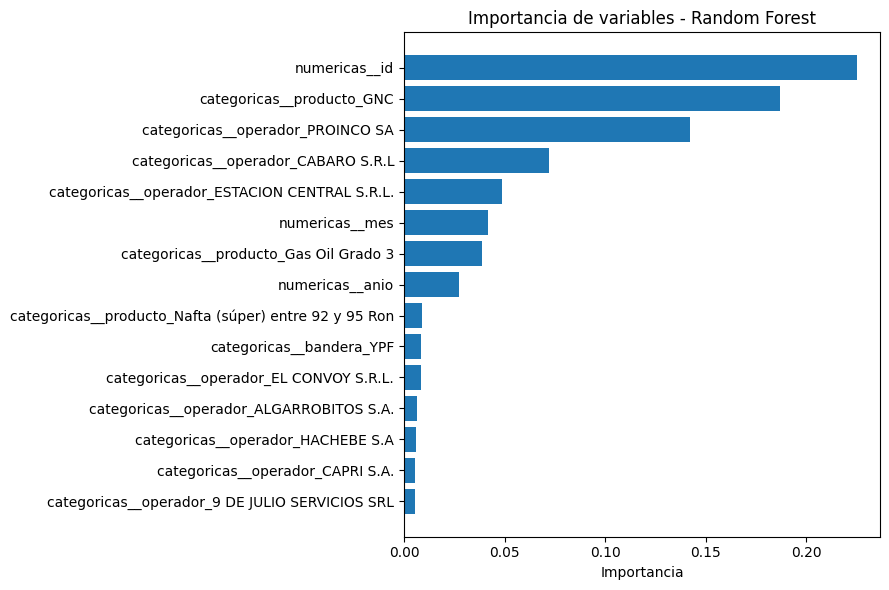

In [43]:

for nombre in ["Árbol de Decisión", "Random Forest"]:

    modelo = modelos[nombre]
    estimador = modelo.named_steps["modelo"]

    nombres_variables = (
        modelo.named_steps["preprocesamiento"]
        .get_feature_names_out()
    )

    importancias = pd.DataFrame({
        "Variable": nombres_variables,
        "Importancia": estimador.feature_importances_
    })

    importancias = importancias.sort_values(
        by="Importancia",
        ascending=False
    ).head(15)

    print(f"Top 15 variables - {nombre}")
    display(importancias)

    datos_grafico = importancias.sort_values(
        by="Importancia",
        ascending=True
    )

    plt.figure(figsize=(9, 6))

    plt.barh(
        datos_grafico["Variable"],
        datos_grafico["Importancia"]
    )

    plt.xlabel("Importancia")
    plt.title(f"Importancia de variables - {nombre}")
    plt.tight_layout()
    plt.show()